# Completed baseline reference

All executable TODO placeholders have been filled. Original report questions and research-extension section are retained for you to answer. No real-data training results are included.

Run from the project folder (or set PROJECT_DIR to its absolute path). Select C16, C17, or BRACS and restart the kernel before each new dataset run. Download the matching HDF5 first. The original configs, splits, selection criterion (validation macro-AUROC + macro-F1), cross-entropy and AdamW are preserved. Padding masks are applied in training/evaluation so padded patches do not affect attention. Results are saved under results/<DATASET>/.


# ECE1512 Project A - Build an ABMIL training pipeline in PyTorch

This notebook uses pre-extracted whole-slide histopathology features and guides you through a complete PyTorch classification pipeline. The goal is not merely to run ABMIL; it is to understand the code path from data loading to optimization, validation, checkpoint selection, and final testing.

Please complete every cell marked `TODO`. Dataset engineering and metric boilerplate are provided so you can focus on the machine-learning training workflow.

This project requires basic familiarity with Python object-oriented programming (OOP). If you have limited experience with Python OOP, please review the provided introductory video before starting the project.

[PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/introyt1_tutorial.html)

[Python Object-Oriented Programming ](https://www.youtube.com/watch?v=JeznW_7DlB0)

**Research extension:** Propose two research ideas and implement and evaluate one selected idea. Report ABMIL baseline and selected-extension results on **CAMELYON16, CAMELYON17, and BRACS**, using the same features and train/validation/test splits within each dataset.


## Learning objectives

After this project you should be able to explain and implement:

1. `Dataset` vs. `DataLoader`, batching, shuffling.
2. `nn.Module`, trainable parameters, and `forward()`.
3. A classification loss and optimizer.
4. The training sequence `zero_grad -> forward -> loss -> backward -> step`.
5. The difference between `model.train()` and `model.eval()`.

## Step 0. Download Pre-extracted WSI Features & Select the Project Directory
Download the required feature file(s) from Zenodo or Hugging Face:

https://zenodo.org/records/23130543

https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature


Place the HDF5 file under the path expected by your YAML configuration in the `config/`, or edit data_dir in the YAML file.


In [ ]:
!pip install -q torchmetrics h5py pandas scikit-learn pyyaml matplotlib openslide-python openslide-bin


In [ ]:
import os, sys, copy, time
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Project helper imports appear after PROJECT_DIR is configured.


PyTorch: 2.11.0+cpu
CUDA available: False


If you are using Google Colab with Drive, mount Drive first and change `PROJECT_DIR`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path
import subprocess

project = Path('/content/drive/MyDrive/Project_A_ABMIL_Completed')

for dataset in ['C16', 'C17', 'BRACS']:
    folder = project / 'feature' / dataset
    folder.mkdir(parents=True, exist_ok=True)

    filename = 'patch_feats_pretrain_medical_ssl.h5'
    url = (
        'https://huggingface.co/datasets/LeonYe/'
        f'ECE1512-WSI-Feature/resolve/main/feature/{dataset}/{filename}'
    )

    print(f'Downloading {dataset}...')
    subprocess.run(
        ['wget', '-c', url, '-O', str(folder / filename)],
        check=True
    )

In [ ]:
# # Optional in Google Colab:
# from google.colab import drive
# drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/Project_A_ABMIL_Completed'  # Folder containing this notebook and config/
DATASET = 'BRACS'  # Choose: 'C16', 'C17', or 'BRACS'

PROJECT_DIR = str(Path(PROJECT_DIR).expanduser().resolve())
os.chdir(PROJECT_DIR)

CONFIG_FILES = {
    'C16': 'camelyon16_medical_ssl_config.yml',
    'C17': 'camelyon17_medical_ssl_config.yml',
    'BRACS': 'bracs_medical_ssl_config.yml',
}
CONFIG_PATH = os.path.join(PROJECT_DIR, 'config', CONFIG_FILES[DATASET])

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

print('Project:', os.path.abspath(PROJECT_DIR))
print('Config :', CONFIG_PATH)

from wsi_visualization import visualize_wsi_attention


Project: /content/drive/MyDrive/Project_A_ABMIL_Completed
Config : /content/drive/MyDrive/Project_A_ABMIL_Completed/config/bracs_medical_ssl_config.yml


In [ ]:
from dataloader import build_HDF5_feat_dataset, mil_collate_fn
from utils import load_config, seed_everything, infer_feature_dim, classification_metrics

conf = load_config(CONFIG_PATH)
seed_everything(int(conf.seed))
print(conf)

if os.path.exists(conf.data_dir):
    print('Feature file exists:', os.path.exists(conf.data_dir), conf.data_dir)
else:
    print('\nDownload the required feature file from: https://zenodo.org/records/23130543')
    print('Then update data_dir in:', CONFIG_PATH)


Struct(B=1, D_attn=128, D_feat=384, D_inner=256, data_dir='./feature/BRACS/patch_feats_pretrain_medical_ssl.h5', dataset='BRACS', dataset_csv_dir='./dataset_csv', droprate=0.0, lr=0.0001, n_class=7, n_res=0, n_shot=0, n_worker=0, pin_memory=True, seed=42, train_epoch=30, warmup_epoch=3, wd=1e-05)
Feature file exists: True ./feature/BRACS/patch_feats_pretrain_medical_ssl.h5


# Step 1 - Dataset and DataLoader

`build_HDF5_feat_dataset` is provided. It creates train/validation/test `Dataset` objects without loading all slide features into memory at once.


Complete the three `DataLoader` definitions. Think about which split should be shuffled.

[Download WSI datasets](https://zenodo.org/records/23130543)

[Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)


[PyTorch DataLoader](https://docs.pytorch.org/docs/2.14/data.html#torch.utils.data.DataLoader)


[PyTorch Datasets](https://docs.pytorch.org/vision/stable/datasets.html)


In [ ]:
train_data, val_data, test_data = build_HDF5_feat_dataset(conf.data_dir, conf)
conf.D_feat = infer_feature_dim(train_data)
print('Split sizes: Train {}, Validation {}, Test {};'.format(len(train_data), len(val_data), len(test_data)))
print("Feature Shape: {};".format(tuple(train_data[1]['input'].shape)))
print("Label: {}; \nSlide ID: {}.".format(train_data[1]['label'], train_data[1]['slide_id']))

Split sizes: Train 389, Validation 62, Test 86;
Feature Shape: (7540, 384);
Label: 1; 
Slide ID: BRACS_1003659.


In [ ]:
batch_size=conf.B
num_workers=int(conf.n_worker)
pin_memory=bool(conf.pin_memory) and torch.cuda.is_available()
collate_fn=mil_collate_fn
print("DataLoader args: Batch size {}; \n \
      # CPUs {};  \n \
      pin_memory {};  \n \
      collate_fn {}".format(batch_size, num_workers, pin_memory, collate_fn))


DataLoader args: Batch size 1; 
       # CPUs 0;  
       pin_memory False;  
       collate_fn <function mil_collate_fn at 0x7af9534337e0>


In [ ]:
# Completed 1A: create the training DataLoader. Training data should be shuffled.
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=pin_memory, collate_fn=collate_fn)

# Completed 1B: create validation and test DataLoaders. Do not shuffle them.
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin_memory, collate_fn=collate_fn)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin_memory, collate_fn=collate_fn)


In [ ]:
# Inspect one MIL batch.
batch = next(iter(train_loader))
print('input:', tuple(batch['input'].shape), batch['input'].dtype)
print('label:', tuple(batch['label'].shape), batch['label'].dtype)
print('slide IDs:', batch['slide_id'])

input: (1, 16307, 384) torch.float32
label: (1,) torch.int64
slide IDs: ['BRACS_1915']


**Questions for your report:**

- What is the difference between a `Dataset` and a `DataLoader`?
- Which Dataloader should use `shuffle=True`? Why?
- For a batch with input shape `[B, N, D]`, what do `B`, `N`, and `D` mean in this project?


# Step 2 - Implement the ABMIL model

For each patch feature $h_i$, the gated attention score follows Ilse et al. (2018):

$$
a_i = w^T\left[\tanh(Vh_i) \odot \sigma(Uh_i)\right].
$$

The attention logits are normalized over instances:

$$
\alpha_i = \frac{\exp(a_i)}{\sum_j \exp(a_j)},
$$

and the slide representation is

$$
z = \sum_i \alpha_i h_i.
$$

You will implement the learnable layers and the key `forward()` operations.

[Custom nn Modules](https://docs.pytorch.org/tutorials/beginner/examples_nn/polynomial_module.html)

[nn.Linear](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Linear.html)

[nn.modules.dropout](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Dropout.html)

[nn.ReLU](https://docs.pytorch.org/docs/2.14/generated/torch.nn.ReLU.html)

[torch.nn.functional.softmax (F.softmax)](https://docs.pytorch.org/docs/2.14/generated/torch.nn.functional.softmax.html)

[torch.bmm](https://docs.pytorch.org/docs/2.14/generated/torch.bmm.html)

In [ ]:
class Classifier1FC(nn.Module):
    def __init__(self, n_channels, n_classes, droprate=0.0):
        super().__init__()
        self.dropout = nn.Dropout(droprate) if droprate > 0 else nn.Identity()
        # Completed 2A: one linear layer from n_channels to n_classes.
        self.fc = nn.Linear(n_channels, n_classes)

    def forward(self, x):
        # Completed 2B: apply dropout, then the classifier.
        return self.fc(self.dropout(x))


class DimReduction(nn.Module):
    def __init__(self, n_channels, m_dim):
        super().__init__()
        # Completed 2C: project patch features to m_dim and use ReLU.
        self.fc = nn.Linear(n_channels, m_dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        # Completed 2D: linear projection followed by ReLU.
        return self.relu(self.fc(x))


class AttentionGated(nn.Module):
    def __init__(self, L=256, D=128, K=1):
        super().__init__()
        self.attention_V = nn.Sequential(nn.Linear(L, D), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(L, D), nn.Sigmoid())
        self.attention_weights_w = nn.Linear(D, K)

    def forward(self, x):
        # x: [B, N, L]
        # Completed 2E: implement the two gated branches.
        a_v = self.attention_V(x)
        a_u = self.attention_U(x)

        a = self.attention_weights_w(a_v * a_u)
        return a.transpose(1, 2)


class ABMIL(nn.Module):
    def __init__(self, conf):
        super().__init__()
        self.dimreduction = DimReduction(conf.D_feat, conf.D_inner)
        self.attention = AttentionGated(conf.D_inner, conf.D_attn, K=1)
        self.classifier = Classifier1FC(conf.D_inner, conf.n_class, conf.droprate)

    def forward(self, x, return_attention=False, mask=None):
        # x: [B, N, D_feat]
        med_feat = self.dimreduction(x)       # [B, N, D_inner]
        a_logits = self.attention(med_feat)   # [B, 1, N]


        # Completed 2G: normalize attention logits over the instance dimension.
        # Exclude padded patches when a batch contains different bag sizes.
        if mask is not None:
            if not mask.any(dim=1).all():
                raise ValueError("Every slide must have at least one valid patch.")
            a_logits = a_logits.masked_fill(~mask.unsqueeze(1), float("-inf"))
        attention = F.softmax(a_logits, dim=-1)

        # Completed 2H: weighted aggregation. torch.bmm is useful here.
        bag_feat = torch.bmm(attention, med_feat).squeeze(1)

        # Completed 2I: classify the slide representation.
        logits = self.classifier(bag_feat)

        if return_attention:
            return logits, attention
        return logits


**Sanity Check**

Before running the full training pipeline, check the tensor shapes and attention normalization.


In [ ]:
model_cpu = ABMIL(conf).eval()

x_demo = torch.randn(2, 7, conf.D_feat)


with torch.no_grad():
    logits_demo, attn_demo = model_cpu(x_demo, return_attention=True)

print('logits:', logits_demo.shape)
print('attention:', attn_demo.shape)
print('attention sums:', attn_demo.sum(dim=-1))

assert logits_demo.shape == (2, int(conf.n_class))
assert attn_demo.shape == (2, 1, 7)
torch.testing.assert_close(attn_demo.sum(dim=-1), torch.ones(2, 1))
print('Sanity check passed.')


logits: torch.Size([2, 7])
attention: torch.Size([2, 1, 7])
attention sums: tensor([[1.0000],
        [1.0000]])
Sanity check passed.


**Questions:**

- Which tensors in your model contain trainable parameters?
- What properties do attention weights have after softmax?
- Could we replace softmax with another function?


# Step 3 - Device, loss, and optimizer

For multi-class slide classification, use cross-entropy as the baseline objective and AdamW as the baseline optimizer. Complete the code below.

[nn.CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html)

[torch.optim.AdamW](https://docs.pytorch.org/docs/2.14/generated/torch.optim.AdamW.html)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ABMIL(conf).to(device)

# Completed 3A: define the multi-class classification loss.
criterion = nn.CrossEntropyLoss()

# Completed 3B: create AdamW and pass the model parameters, learning rate, and weight decay.
optimizer = torch.optim.AdamW(model.parameters(), lr=conf.lr, weight_decay=conf.wd)

print('Device:', device)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))


Device: cpu
Trainable parameters: 166280


# Step 4 - Complete one training epoch

The essential PyTorch optimization sequence is:

`model.train()` -> move tensors to device -> `zero_grad()` -> forward pass -> compute loss -> `backward()` -> `step()`.

Implement this sequence yourself. This is one of the main learning objectives of the project.

[Training with PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html)

[train() vs eval()](https://discuss.pytorch.org/t/model-train-and-model-eval-vs-model-and-model-eval/5744)

In [ ]:
def train_one_epoch(model, criterion, data_loader, optimizer, device):
    # Completed 4A: put the model in training mode.
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for data in data_loader:
        # Completed 4B: move input and labels to the selected device.
        bag = data["input"].to(device, dtype=torch.float32)
        labels = data["label"].to(device, dtype=torch.long)

        # Completed 4C: clear gradients from the previous iteration.
        optimizer.zero_grad(set_to_none=True)

        # Completed 4D: forward pass.
        logits = model(bag, mask=data["mask"].to(device))

        # Completed 4E: compute the loss.
        loss = criterion(logits, labels)

        # Completed 4F: back-propagate gradients.
        loss.backward()

        # Completed 4G: update the model parameters.
        optimizer.step()

        batch_size = labels.shape[0]
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += batch_size

    return {
        'loss': total_loss / total_examples,
        'acc': 100.0 * total_correct / total_examples,
    }


# Step 5 - Validation and test evaluation

Evaluation should not update the model. Complete the missing lines and use the provided metric helper for macro-AUROC and macro-F1.


In [ ]:
@torch.no_grad()
def evaluate(model, criterion, data_loader, device, conf):
    # Completed 5A: switch to evaluation mode.
    model.eval()

    total_loss = 0.0
    total_examples = 0
    probabilities_all = []
    labels_all = []

    for data in data_loader:
        # Completed 5B: move data to device.
        bag = data["input"].to(device, dtype=torch.float32)
        labels = data["label"].to(device, dtype=torch.long)

        # Completed 5C: forward pass and loss.
        logits = model(bag, mask=data["mask"].to(device))
        loss = criterion(logits, labels)

        # Completed 5D: convert class logits into probabilities.
        probabilities = F.softmax(logits, dim=1)

        total_loss += loss.item() * labels.shape[0]
        total_examples += labels.shape[0]
        probabilities_all.append(probabilities)
        labels_all.append(labels)

    probabilities_all = torch.cat(probabilities_all, dim=0)
    labels_all = torch.cat(labels_all, dim=0)
    metrics = classification_metrics(probabilities_all, labels_all, conf.n_class)
    metrics['loss'] = total_loss / total_examples
    return metrics


**Checkpoint questions:**

- Why are `model.eval()` and `torch.no_grad()` different concepts?
- What would happen if gradients were accumulated because `optimizer.zero_grad()` was omitted?
- Why must the test set not be used to choose the best epoch?


# Step 6 - Train, validate, and select the best checkpoint

Use the validation set to choose the best epoch. The test set must remain untouched until model selection is complete.

For debugging, set `NUM_EPOCHS = 2`. For your reported baseline, use the full configured epoch count unless instructed otherwise.


In [ ]:
NUM_EPOCHS = int(conf.train_epoch)  # You may temporarily set this to 2 while debugging.

best_score = float('-inf')
best_epoch = -1
best_model_state = None
history = []

for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_metrics = train_one_epoch(model, criterion, train_loader, optimizer, device)
    val_metrics = evaluate(model, criterion, val_loader, device, conf)

    # Baseline selection criterion: macro-AUROC + macro-F1.
    score = val_metrics['auc'] + val_metrics['f1']

    if score > best_score:
        best_score = score
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())
    row = {
        'epoch': epoch,
        'train_loss': train_metrics['loss'],
        'train_acc': train_metrics['acc'],
        'val_loss': val_metrics['loss'],
        'val_acc': val_metrics['acc'],
        'val_auc': val_metrics['auc'],
        'val_f1': val_metrics['f1'],
    }
    history.append(row)
    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
          f"train loss={row['train_loss']:.4f} acc={row['train_acc']:.2f} | "
          f"val loss={row['val_loss']:.4f} auc={row['val_auc']:.3f} f1={row['val_f1']:.3f} | "
          f"best={best_epoch+1} | {time.time()-start:.1f}s")

assert best_model_state is not None


Epoch 01/30 | train loss=1.5955 acc=44.73 | val loss=1.7553 auc=0.704 f1=0.183 | best=1 | 82.4s
Epoch 02/30 | train loss=1.1957 acc=55.01 | val loss=1.5603 auc=0.789 f1=0.194 | best=2 | 81.5s
Epoch 03/30 | train loss=1.0273 acc=61.70 | val loss=1.3887 auc=0.823 f1=0.348 | best=3 | 83.1s
Epoch 04/30 | train loss=0.9250 acc=67.35 | val loss=1.5576 auc=0.808 f1=0.286 | best=3 | 93.0s
Epoch 05/30 | train loss=0.8674 acc=68.38 | val loss=1.4083 auc=0.825 f1=0.395 | best=5 | 89.1s
Epoch 06/30 | train loss=0.8013 acc=71.72 | val loss=1.3943 auc=0.829 f1=0.340 | best=5 | 82.3s
Epoch 07/30 | train loss=0.7419 acc=73.01 | val loss=1.4536 auc=0.825 f1=0.352 | best=5 | 92.1s
Epoch 08/30 | train loss=0.7230 acc=72.24 | val loss=1.4838 auc=0.825 f1=0.308 | best=5 | 82.6s


KeyboardInterrupt: 

In [ ]:
# Plot learning curves.
epochs = [x['epoch'] + 1 for x in history]
plt.figure(figsize=(7, 4))
plt.plot(epochs, [x['train_loss'] for x in history], label='train loss')
plt.plot(epochs, [x['val_loss'] for x in history], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.2)
RESULT_DIR = Path(PROJECT_DIR) / 'results' / DATASET
RESULT_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(RESULT_DIR / 'loss_curves.png', dpi=180, bbox_inches='tight')
plt.show()


# Step 7 - Final held-out test evaluation

Only now, after the best checkpoint has been chosen from validation performance, load it and evaluate once on the test set.


In [ ]:
model.load_state_dict(best_model_state)
test_metrics = evaluate(model, criterion, test_loader, device, conf)

print('Best validation epoch:', best_epoch + 1)
print('Final test metrics:')
for key, value in test_metrics.items():
    print(f'  {key}: {value:.4f}')


# Save actual experiment outputs for the report and teammate handoff.
import json, csv, platform
RESULT_DIR = Path(PROJECT_DIR) / 'results' / DATASET
RESULT_DIR.mkdir(parents=True, exist_ok=True)
torch.save({
    'model_state_dict': {k: v.detach().cpu() for k, v in best_model_state.items()},
    'config': vars(conf), 'best_epoch': best_epoch + 1,
}, RESULT_DIR / 'best_model.pt')
with (RESULT_DIR / 'history.csv').open('w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=list(history[0]))
    writer.writeheader()
    writer.writerows(history)
summary = {
    'dataset': DATASET, 'best_epoch': best_epoch + 1,
    'epochs_run': NUM_EPOCHS, 'test_metrics': test_metrics,
    'config': vars(conf), 'torch_version': torch.__version__,
    'python_version': platform.python_version(), 'device': str(device),
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}
with (RESULT_DIR / 'metrics.json').open('w') as f:
    json.dump(summary, f, indent=2)
splits = {name: list(data.data_names) for name, data in
          [('train', train_data), ('val', val_data), ('test', test_data)]}
with (RESULT_DIR / 'splits.json').open('w') as f:
    json.dump(splits, f, indent=2)
print('Saved experiment outputs to:', RESULT_DIR)


# Step 8 -  Inspect Attention on One Slide

Attention is useful for understanding which instances contribute strongly to the learned bag representation, but attention weights should not automatically be interpreted as causal explanations.


In [ ]:
one_batch = mil_collate_fn([test_data[0]])
model.eval()
with torch.no_grad():
    logits, attention = model(
        one_batch['input'].to(device, dtype=torch.float32),
        return_attention=True,
    )

print('Slide:', one_batch['slide_id'][0])
print('Predicted class:', int(logits.argmax(dim=1)[0]))
print('Attention shape:', tuple(attention.shape))
print('Attention sum for first slide:', float(attention[0].sum()))


## Visualize Attention on Whole-Slide Images (WSIs)

Before running the attention visualization, please complete the following steps:

1. Visit the [ECE1512-WSI-Feature dataset on Hugging Face](https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature)

2. Download the original WSIs `test_067.tif` and `test_068.tif` and the corresponding tumor annotation file `test_068.xml`.

3. Create a folder named `slide/` under your project directory and place the downloaded files in this folder.

Run this cell after training and final test evaluation, with `DATASET = 'C16'`. It restores `best_model_state` and plots the two slides in `PROJECT_DIR/slide`:

- **test_068 (tumor):** attention overlay and green contours from `test_068.xml`, including a zoom of the annotated region.
- **test_067 (normal):** attention overlay without annotation contours, including a zoom around the highest-attention patch.

The blue rectangle marks the zoom shown on the right. Colors show **attention percentiles within each slide**, not patch tumor probabilities; areas without extracted patches stay transparent. The displayed `P(tumor)` is the model's slide-level prediction.

HDF5 patch coordinates and XML contour coordinates are assumed to be expressed in level-0 `(x, y)`  coordinates; patch coordinates are treated as top-left corners. The function parameter `patch_size_level0=512` is an editable **assumption** for the patch footprint because these HDF5 files do not store patch-size metadata. Match it to the feature extractor's patch size for an exact footprint. All visualization functions are in `wsi_visualization.py`; the cell below only calls `visualize_wsi_attention`.

[OpenSlide Python](https://openslide.org/api/python/) reads a thumbnail and a pyramid-level crop rather than loading the full-resolution WSI into memory. If dependencies are missing, run `%pip install openslide-python openslide-bin` and restart the kernel if needed. Raw per-patch attention and coordinates are retained in `attention_visualizations`.


In [ ]:
from pathlib import Path
import subprocess

slide_dir = Path(PROJECT_DIR) / 'slide'
slide_dir.mkdir(parents=True, exist_ok=True)

base_url = (
    'https://huggingface.co/datasets/LeonYe/'
    'ECE1512-WSI-Feature/resolve/main/slide/'
)

for filename in ['test_067.tif', 'test_068.tif', 'test_068.xml']:
    subprocess.run(
        ['wget', '-c', base_url + filename,
         '-O', str(slide_dir / filename)],
        check=True
    )

In [ ]:
if DATASET == 'C16':
    attention_visualizations = visualize_wsi_attention(model, conf, PROJECT_DIR, best_model_state)

    torch.save(attention_visualizations, RESULT_DIR / 'attention_visualizations.pt')


# Step 9 - Research extension: propose two ideas, implement one of them

After completing the ABMIL baseline, propose **two distinct research ideas**. Select **one** for implementation and evaluation on **CAMELYON16 (C16), CAMELYON17 (C17), and BRACS**. You may explore explainability, more advanced model structures, improved objectives beyond cross-entropy, or another well-motivated direction.

**A negative result will not be penalized if the design choices, experiments, observations, and possible reasons for failure are well justified.** Report evidence relevant to your hypothesis: an explainability idea, for example, needs an explanation evaluation in addition to classification results.

Feel free to contact your TA to discuss your research ideas.

## Research Proposals

### Proposal 1: Multi-Head Attention with a Diversity Constraint

We propose extending ABMIL with multiple attention branches to capture
complementary diagnostic information. Each branch produces an attention
distribution and a slide representation:

$$
\alpha^{(k)} = \operatorname{softmax}(s^{(k)}), \qquad
v_k = \sum_{i=1}^{N}\alpha_i^{(k)}h_i.
$$

The branch representations are concatenated for classification. To
discourage redundant attention patterns, we propose minimizing the
average pairwise cosine similarity between attention distributions:

$$
L_{\mathrm{div}} =
\frac{2}{K(K-1)}
\sum_{k<l}
\frac{\alpha^{(k)\top}\alpha^{(l)}}
{\|\alpha^{(k)}\|_2\|\alpha^{(l)}\|_2},
\qquad K>1.
$$

The proposed objective is:

$$
L_1 = CE(p,y) + \beta L_{\mathrm{div}}.
$$

Here, $K$ is the number of attention branches and $\beta$ controls the
diversity constraint. Excessive diversity may encourage attention to
irrelevant regions, so these settings would be selected using validation
data. This proposal is not implemented in this project.

### Proposal 2: Feature Perturbation with a Consistency Constraint

We investigate whether stable predictions under small feature
perturbations can improve ABMIL generalization without changing its
architecture. Gaussian noise is added only to valid patch features:

$$
\widetilde{X} = X + \sigma(M \odot \epsilon),
\qquad \epsilon \sim \mathcal{N}(0,I).
$$

Here, $M$ is the valid-patch mask, broadcast over feature dimensions,
and $\sigma$ controls noise strength. The same model processes both inputs:

$$
p = \operatorname{softmax}(f_\theta(X,M)), \qquad
q = \operatorname{softmax}(f_\theta(\widetilde{X},M)).
$$

The training objective combines average cross-entropy with symmetric
KL divergence:

$$
L_2 =
\frac{CE(p,y)+CE(q,y)}{2}
+
\frac{\lambda}{2}
\left[D_{KL}(p\|q)+D_{KL}(q\|p)\right].
$$

Here, $y$ is the slide label and $\lambda$ controls consistency
regularization. Both branches receive gradients. The classification term
encourages correct predictions, while the consistency term discourages
sensitivity to small perturbations.

We implement Proposal 2 on C16, C17, and BRACS, using
$\sigma\in\{0.01,0.05\}$ and $\lambda\in\{0.1,1.0\}$.
Each configuration is trained for 30 epochs. We retain the baseline
features and data splits, select configurations and checkpoints using
validation macro-AUROC plus macro-F1, and test without noise.

We compare accuracy, macro-AUROC, macro-F1, and loss curves against
standard ABMIL. Improvements and decreases will be discussed based on
the observed results; improved performance is not assumed.




In [ ]:
from pathlib import Path
import json
import torch

PROJECT = Path(PROJECT_DIR).resolve()
RUN_NAME = "consistency_v2"

script = PROJECT / "research_extension.py"
if not script.is_file():
    raise FileNotFoundError(
        f"Research extension script not found: {script}"
    )

for dataset in ["C16", "C17", "BRACS"]:
    baseline_dir = PROJECT / "results" / dataset

    required_files = [
        baseline_dir / "metrics.json",
        baseline_dir / "splits.json",
        PROJECT / "feature" / dataset /
        "patch_feats_pretrain_medical_ssl.h5",
    ]

    for path in required_files:
        if not path.is_file():
            raise FileNotFoundError(f"Required file not found: {path}")

    summary = json.loads(
        (baseline_dir / "metrics.json").read_text()
    )
    print(dataset, "baseline test metrics:", summary["test_metrics"])

print("Training device:", "CUDA GPU" if torch.cuda.is_available() else "CPU")
print("Extension results:", PROJECT / "results_extension" / RUN_NAME)

C16 baseline test metrics: {'auc': 0.8704081773757935, 'acc': 82.94573426246643, 'f1': 0.8159055709838867, 'loss': 0.41645895779428843}
C17 baseline test metrics: {'auc': 0.8350513577461243, 'acc': 78.99999618530273, 'f1': 0.5258098244667053, 'loss': 0.7031685425888281}
BRACS baseline test metrics: {'auc': 0.8154810667037964, 'acc': 47.67441749572754, 'f1': 0.4076976478099823, 'loss': 1.3559640832028763}
Training device: CPU
Extension results: /content/drive/MyDrive/Project_A_ABMIL_Completed/results_extension/consistency_v2


In [ ]:
from pathlib import Path
from datetime import datetime
import json
import shutil

PROJECT = Path(
    "/content/drive/MyDrive/Project_A_ABMIL_Completed"
)
RUN_NAME = "consistency_v1"
RESULT = PROJECT / "results_extension" / RUN_NAME / "BRACS"

assert (PROJECT / "research_extension.py").is_file()
assert RESULT.is_dir(), f"Experiment directory not found: {RESULT}"

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
manifest = RESULT / "experiment_manifest.json"

# Update only storage paths if the previous runtime used /content/gdrive.
# Keep all experimental settings and hashes unchanged.
data = json.loads(manifest.read_text())
updated = json.loads(json.dumps(data))

updated["config"]["data_dir"] = str(
    PROJECT / "feature/BRACS/patch_feats_pretrain_medical_ssl.h5"
)
updated["config"]["dataset_csv_dir"] = str(PROJECT / "dataset_csv")

if updated != data:
    shutil.copy2(
        manifest,
        manifest.with_name(f"experiment_manifest_backup_{stamp}.json"),
    )
    manifest.write_text(json.dumps(updated, indent=2))
    print("Storage paths updated. Original manifest backed up.")

# Preserve completed configurations and archive incomplete ones.
if (RESULT / "metrics.json").is_file():
    print("BRACS already has final results. No training is needed.")
else:
    for folder in sorted(RESULT.glob("sigma_*_lambda_*")):
        if not folder.is_dir():
            continue

        if (folder / "selection.json").is_file():
            print("Completed; will reuse:", folder.name)
        else:
            backup = folder.with_name(
                f"incomplete_{stamp}_{folder.name}"
            )
            folder.rename(backup)
            print("Incomplete configuration backed up:", folder.name)

print("Run directory:", RESULT)

Storage paths updated. Original manifest backed up.
Completed; will reuse: sigma_0.01_lambda_0.1
Completed; will reuse: sigma_0.01_lambda_1
Incomplete configuration backed up: sigma_0.05_lambda_0.1
Run directory: /content/drive/MyDrive/Project_A_ABMIL_Completed/results_extension/consistency_v1/BRACS


In [ ]:
from pathlib import Path
import subprocess
import h5py

PROJECT = Path(
    "/content/drive/MyDrive/Project_A_ABMIL_Completed"
)
RUN_NAME = "consistency_v1"

# Results must remain accessible on Drive.
assert (PROJECT / "research_extension.py").is_file(), (
    "The Drive project is not accessible. Mount Google Drive first."
)

LOCAL = Path(
    "/content/bracs_cache/patch_feats_pretrain_medical_ssl.h5"
)
LOCAL.parent.mkdir(parents=True, exist_ok=True)

if not LOCAL.is_file():
    partial = LOCAL.with_suffix(".h5.download.part")
    url = (
        "https://huggingface.co/datasets/LeonYe/"
        "ECE1512-WSI-Feature/resolve/main/feature/BRACS/"
        "patch_feats_pretrain_medical_ssl.h5"
    )

    print("Downloading BRACS features to local storage...", flush=True)

    subprocess.run(
        ["wget", "-c", "--tries=5", url, "-O", str(partial)],
        check=True,
    )

    with h5py.File(partial, "r") as h5:
        assert len(h5) > 0

    partial.replace(LOCAL)

with h5py.File(LOCAL, "r") as h5:
    print("Local feature file is readable.")
    print("Number of slides:", len(h5))

print("Local file:", LOCAL)

Local feature file is readable.
Number of slides: 537
Local file: /content/bracs_cache/patch_feats_pretrain_medical_ssl.h5


In [ ]:
from datetime import datetime
import subprocess
import sys

RESULT = PROJECT / "results_extension" / RUN_NAME / "BRACS"

assert LOCAL.is_file(), "Local BRACS features were not found."
assert RESULT.is_dir(), "The existing BRACS experiment was not found."

# Back up incomplete configurations; preserve completed ones.
stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

if not (RESULT / "metrics.json").is_file():
    for folder in sorted(RESULT.glob("sigma_*_lambda_*")):
        if not folder.is_dir():
            continue

        if (folder / "selection.json").is_file():
            print("Reusing completed configuration:", folder.name)
        else:
            backup = folder.with_name(
                f"incomplete_{stamp}_{folder.name}"
            )
            folder.rename(backup)
            print("Backed up incomplete configuration:", folder.name)

# Read features locally while saving results to the existing Drive run.
launcher = RESULT / "run_with_local_features.py"

launcher.write_text('''
import os
import sys
from pathlib import Path

project, local_file, run_name = sys.argv[1:4]
sys.path.insert(0, project)
os.chdir(project)

import research_extension as extension

OriginalDataset = extension.HDF5FeatureDataset

class LocalFeatureDataset(OriginalDataset):
    def __init__(self, file_path, slide_names, conf):
        if str(conf.dataset).upper() == "BRACS":
            file_path = local_file
        super().__init__(file_path, slide_names, conf)

extension.HDF5FeatureDataset = LocalFeatureDataset

print("Reading BRACS features from:", local_file, flush=True)

sys.argv = [
    str(Path(project) / "research_extension.py"),
    "--project", project,
    "--run", run_name,
    "--datasets", "BRACS",
    "--sigmas", "0.01", "0.05",
    "--weights", "0.1", "1.0",
]

extension.main()
''')

command = [
    sys.executable, "-u", str(launcher),
    str(PROJECT), str(LOCAL), RUN_NAME,
]

with subprocess.Popen(
    command,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
) as process:
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        return_code = process.wait()
    except BaseException:
        process.terminate()
        process.wait()
        raise

if return_code != 0:
    raise RuntimeError("Training failed. Check the traceback above.")

print("BRACS completed. Results saved to:", RESULT)

Reusing completed configuration: sigma_0.01_lambda_0.1
Reusing completed configuration: sigma_0.01_lambda_1
Backed up incomplete configuration: sigma_0.05_lambda_0.1
Reading BRACS features from: /content/bracs_cache/patch_feats_pretrain_medical_ssl.h5
sigma_0.05_lambda_0.1 epoch 1: train=1.6019, val=1.8187, score=0.8745
sigma_0.05_lambda_0.1 epoch 2: train=1.2401, val=1.5357, score=1.0470
sigma_0.05_lambda_0.1 epoch 3: train=1.0633, val=1.4307, score=1.1763
sigma_0.05_lambda_0.1 epoch 4: train=0.9488, val=1.5448, score=1.1545
sigma_0.05_lambda_0.1 epoch 5: train=0.8812, val=1.3608, score=1.1561
sigma_0.05_lambda_0.1 epoch 6: train=0.8070, val=1.4314, score=1.2446
sigma_0.05_lambda_0.1 epoch 7: train=0.7730, val=1.4245, score=1.2605
sigma_0.05_lambda_0.1 epoch 8: train=0.7208, val=1.5022, score=1.2286
sigma_0.05_lambda_0.1 epoch 9: train=0.6714, val=1.5968, score=1.2197
sigma_0.05_lambda_0.1 epoch 10: train=0.6544, val=1.5488, score=1.1866
sigma_0.05_lambda_0.1 epoch 11: train=0.6168, v

In [3]:
from google.colab import drive
from pathlib import Path

mounts = [Path("/content/drive"), Path("/content/gdrive")]

if not any((mount / "MyDrive").is_dir() for mount in mounts):
    drive.mount("/content/drive")

projects = [
    mount / "MyDrive/Project_A_ABMIL_Completed"
    for mount in mounts
]

PROJECT = next(
    (
        project for project in projects
        if (project / "results/C16/metrics.json").is_file()
    ),
    None,
)

if PROJECT is None:
    print("The baseline file was not found at either expected location.")
    for project in projects:
        print("\nProject:", project)
        print("Project exists:", project.is_dir())
        results = project / "results"
        print(
            "Results directory contents:",
            [p.name for p in results.iterdir()]
            if results.is_dir() else "Directory not found",
        )
else:
    RUN = PROJECT / "results_extension/consistency_v1"
    print("Project found:", PROJECT)

    for dataset in ["C16", "C17", "BRACS"]:
        print(
            dataset,
            "baseline:",
            (PROJECT / "results" / dataset / "metrics.json").is_file(),
            "extension:",
            (RUN / dataset / "metrics.json").is_file(),
        )

Mounted at /content/drive
Project found: /content/drive/MyDrive/Project_A_ABMIL_Completed
C16 baseline: True extension: True
C17 baseline: True extension: True
BRACS baseline: True extension: True


In [4]:
import json
import pandas as pd
from IPython.display import display

rows = []

for dataset in ["C16", "C17", "BRACS"]:
    baseline = json.loads(
        (PROJECT / "results" / dataset / "metrics.json").read_text()
    )["test_metrics"]

    summary = json.loads(
        (RUN / dataset / "metrics.json").read_text()
    )
    extension = summary["test_metrics"]

    print(
        f"{dataset}: {summary['selected_candidate']}, "
        f"best epoch = {summary['best_epoch']}"
    )

    for metric in ["acc", "auc", "f1", "loss"]:
        rows.append({
            "Dataset": dataset,
            "Metric": metric,
            "Baseline": baseline[metric],
            "Extension": extension[metric],
            "Delta": extension[metric] - baseline[metric],
        })

comparison = pd.DataFrame(rows)
display(comparison.round(4))

comparison.to_csv(RUN / "final_test_comparison.csv", index=False)
print("Comparison saved.")

C16: sigma_0.01_lambda_0.1, best epoch = 3
C17: sigma_0.01_lambda_1, best epoch = 21
BRACS: sigma_0.05_lambda_0.1, best epoch = 7


,Dataset,Metric,Baseline,Extension,Delta
0,C16,acc,82.9457,88.3721,5.4264
1,C16,auc,0.8704,0.9227,0.0523
2,C16,f1,0.8159,0.8714,0.0554
3,C16,loss,0.4165,0.2700,-0.1465
4,C17,acc,79.0000,80.5000,1.5000
5,C17,auc,0.8351,0.8260,-0.0091
6,C17,f1,0.5258,0.5759,0.0501
7,C17,loss,0.7032,0.7532,0.0500
8,BRACS,acc,47.6744,45.3488,-2.3256
9,BRACS,auc,0.8155,0.8155,0.0000


Comparison saved.


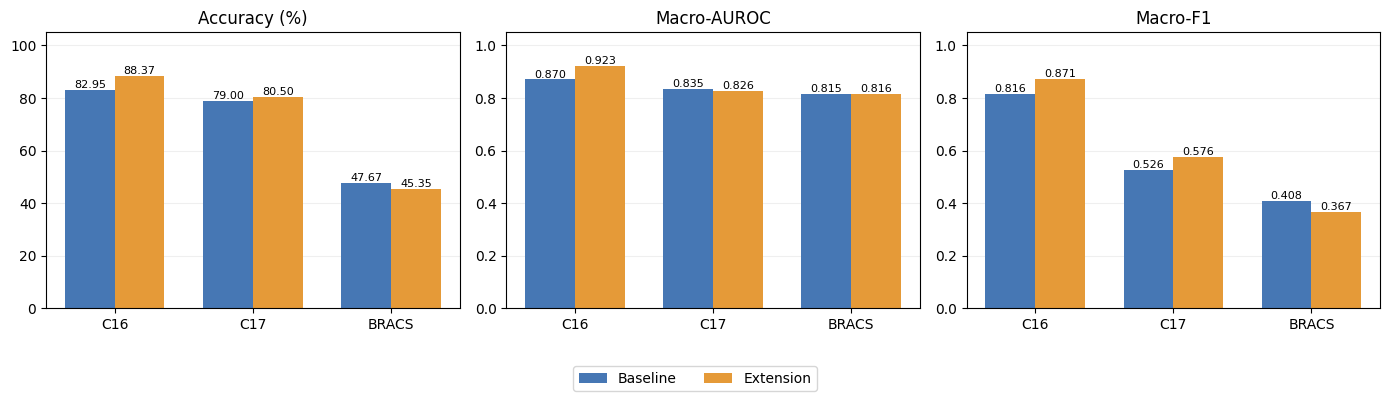

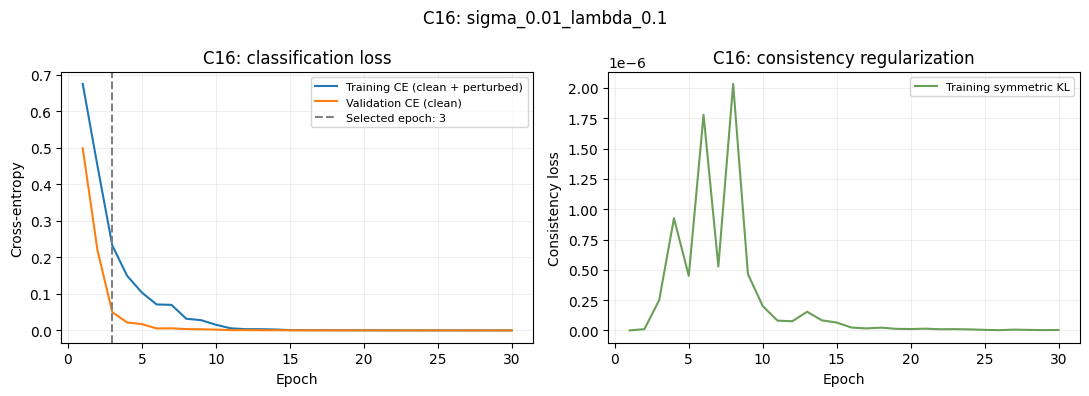

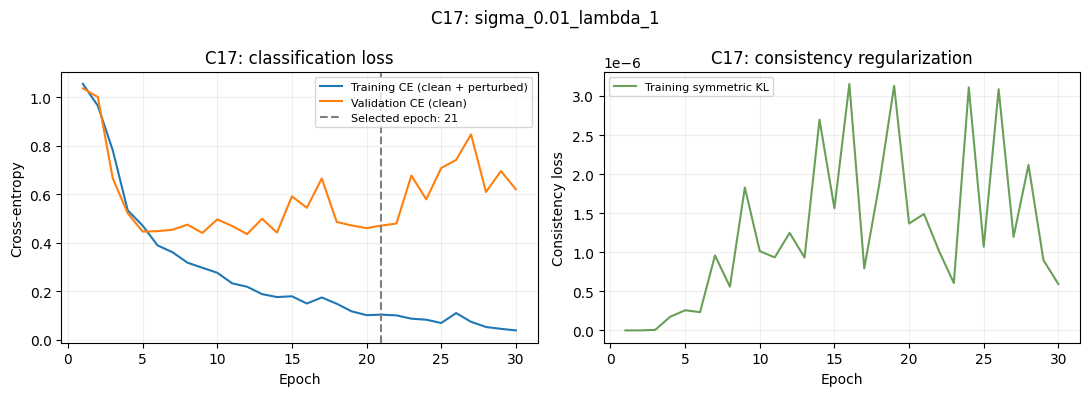

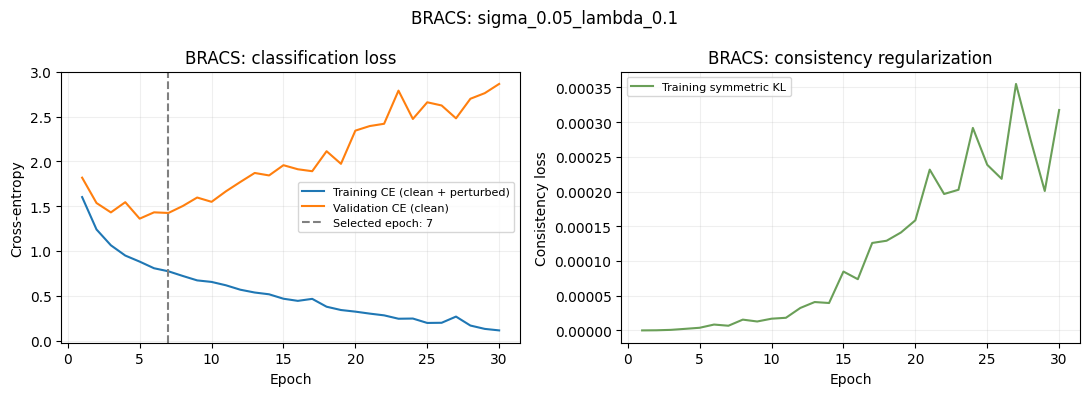

Figures saved to: /content/drive/MyDrive/Project_A_ABMIL_Completed/results_extension/consistency_v1/report_figures


In [5]:
import json
import pandas as pd
import matplotlib.pyplot as plt

OUT = RUN / "report_figures"
OUT.mkdir(parents=True, exist_ok=True)

datasets = ["C16", "C17", "BRACS"]
methods = ["Baseline", "Extension"]
colors = ["#4677B4", "#E59A38"]

# 1. Compare final test metrics.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metric, title in zip(
    axes,
    ["acc", "auc", "f1"],
    ["Accuracy (%)", "Macro-AUROC", "Macro-F1"],
):
    subset = (
        comparison[comparison["Metric"] == metric]
        .set_index("Dataset")
        .loc[datasets]
    )

    for i, method in enumerate(methods):
        positions = [
            j + (i - 0.5) * 0.36
            for j in range(len(datasets))
        ]
        bars = ax.bar(
            positions,
            subset[method],
            width=0.36,
            label=method,
            color=colors[i],
        )
        ax.bar_label(
            bars,
            fmt="%.2f" if metric == "acc" else "%.3f",
            fontsize=8,
        )

    ax.set_xticks(range(len(datasets)), datasets)
    ax.set_title(title)
    ax.set_ylim(0, 105 if metric == "acc" else 1.05)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2)
fig.tight_layout(rect=[0, 0.12, 1, 1])

fig.savefig(OUT / "metric_comparison.png", dpi=300)
fig.savefig(OUT / "metric_comparison.pdf")
plt.show()

# 2. Plot losses for each selected extension configuration.
for dataset in datasets:
    summary = json.loads(
        (RUN / dataset / "metrics.json").read_text()
    )
    candidate = summary["selected_candidate"]
    history = pd.read_csv(
        RUN / dataset / candidate / "history.csv"
    )

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    epochs = history["epoch"]  # Extension epochs are numbered from 1.

    axes[0].plot(
        epochs, history["train_ce_loss"],
        label="Training CE (clean + perturbed)",
    )
    axes[0].plot(
        epochs, history["val_loss"],
        label="Validation CE (clean)",
    )
    axes[0].axvline(
        summary["best_epoch"],
        color="gray",
        linestyle="--",
        label=f"Selected epoch: {summary['best_epoch']}",
    )
    axes[0].set(
        xlabel="Epoch",
        ylabel="Cross-entropy",
        title=f"{dataset}: classification loss",
    )

    axes[1].plot(
        epochs, history["train_consistency_loss"],
        color="#6A9F58",
        label="Training symmetric KL",
    )
    axes[1].set(
        xlabel="Epoch",
        ylabel="Consistency loss",
        title=f"{dataset}: consistency regularization",
    )

    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)

    fig.suptitle(f"{dataset}: {candidate}")
    fig.tight_layout()
    fig.savefig(OUT / f"{dataset}_selected_losses.png", dpi=300)
    fig.savefig(OUT / f"{dataset}_selected_losses.pdf")
    plt.show()

print("Figures saved to:", OUT)

In [3]:
from google.colab import drive
from pathlib import Path

# Mount Google Drive if it is not already mounted.
mounts = [Path("/content/drive"), Path("/content/gdrive")]

if not any((mount / "MyDrive").is_dir() for mount in mounts):
    drive.mount("/content/drive")

# Locate the existing project.
PROJECT = next(
    (
        mount / "MyDrive/Project_A_ABMIL_Completed"
        for mount in mounts
        if (mount / "MyDrive/Project_A_ABMIL_Completed").is_dir()
    ),
    None,
)

if PROJECT is None:
    raise FileNotFoundError(
        "Project folder not found. Check the mounted Google account "
        "and project folder name."
    )

RUN = PROJECT / "results_extension/consistency_v1"
print("Project:", PROJECT)

for dataset in ["C16", "C17", "BRACS"]:
    for name, folder in [
        ("Baseline", PROJECT / "results" / dataset),
        ("Extension", RUN / dataset),
    ]:
        print(
            dataset, name,
            "splits:", (folder / "splits.json").is_file(),
            "metrics:", (folder / "metrics.json").is_file(),
        )

Mounted at /content/drive
Project: /content/drive/MyDrive/Project_A_ABMIL_Completed
C16 Baseline splits: True metrics: True
C16 Extension splits: True metrics: True
C17 Baseline splits: True metrics: True
C17 Extension splits: True metrics: True
BRACS Baseline splits: True metrics: True
BRACS Extension splits: True metrics: True


In [4]:
import json

for dataset in ["C16", "C17", "BRACS"]:
    baseline_dir = PROJECT / "results" / dataset
    extension_dir = RUN / dataset

    baseline_splits = json.loads(
        (baseline_dir / "splits.json").read_text()
    )
    extension_splits = json.loads(
        (extension_dir / "splits.json").read_text()
    )

    assert baseline_splits == extension_splits, (
        f"{dataset}: baseline and extension splits differ."
    )

    split_sets = [
        set(baseline_splits[name])
        for name in ["train", "val", "test"]
    ]
    assert not any(
        split_sets[i] & split_sets[j]
        for i, j in [(0, 1), (0, 2), (1, 2)]
    ), f"{dataset}: overlapping splits."

    summary = json.loads(
        (extension_dir / "metrics.json").read_text()
    )
    selected_dir = extension_dir / summary["selected_candidate"]

    for path in [
        baseline_dir / "history.csv",
        baseline_dir / "best_model.pt",
        selected_dir / "history.csv",
        selected_dir / "selection.json",
        selected_dir / "best_model.pt",
    ]:
        assert path.is_file(), f"Missing file: {path}"

    print(f"{dataset}: saved files and split checks passed.")
    print("Recorded environment:", {
        key: summary.get(key)
        for key in [
            "python_version", "torch_version", "device", "gpu"
        ]
    })

C16: saved files and split checks passed.
Recorded environment: {'python_version': '3.13.16', 'torch_version': '2.11.0+cu130', 'device': 'cuda', 'gpu': 'Tesla T4'}
C17: saved files and split checks passed.
Recorded environment: {'python_version': '3.13.16', 'torch_version': '2.11.0+cu130', 'device': 'cuda', 'gpu': 'Tesla T4'}
BRACS: saved files and split checks passed.
Recorded environment: {'python_version': '3.13.16', 'torch_version': '2.11.0+cpu', 'device': 'cpu', 'gpu': None}
